# WaZP + DES-Y3 combined posterior corner plot — Diemer19 M-c relation, single gamma

Re-plots the combined (bootstrap-pooled) posterior corner plot for
`gamma_scan_outputs/run_2026-07-26T21-20-20/simulation_g00_gamma+0.0` —
the `gamma_inference_diemer.py` production run (`diemer_cm` branch),
using the Diemer & Joyce (2019) concentration-mass relation as the
baseline instead of a fitted power law:

    log10(c) = log10(c_Diemer19(M200m, z)) + gamma * log10(delta_m/delta_m_ref)

`gamma` is the ONLY concentration-related free parameter (the magnitude-
gap slope, same role `gamma_cm` plays in the combined-model runs) — there
is no c0/alpha_cm/beta_cm here. Mass-definition consistency (M200m
throughout, matching `xlensing.model.NFW_Delta_Sigma`) and the model
derivation are in `destacking/model.py`'s `forward_model_diemer`
docstring and `reports/2026-07-26_boost_factors_variance_floor_alpha_cm.tex`.

Combines whatever bootstraps have converged so far WITHOUT stopping the
still-running fit — this notebook only reads completed bootstrap_NNN/
directories. Same presentation as the earlier combined-corner notebooks
(inward ticks, no truth/title, smooth KDE marginals, prior overlay,
summary table).


In [1]:
import os
import json

import numpy as np
import yaml
import matplotlib.pyplot as plt
import corner as _corner
from scipy.stats import norm as sp_norm, uniform as sp_uniform, gaussian_kde

In [ ]:
# ── Config ────────────────────────────────────────────────────────────────
# nautilus output chains live outside the repo (moved 2026-07-27,
# see project memory real-data-relocated).
RUN_DIR = os.path.expanduser("~/destacking_data/output/run_2026-07-26T21-20-20")
SIM_SUBDIR = os.path.join(RUN_DIR, "simulation_g00_gamma+0.0")
OUT_PATH = os.path.join(SIM_SUBDIR, "combined_corner_replot.png")

# Same LaTeX labels used by gamma_inference_diemer.py's _FIT_PARAM_LABELS
# (no c0/alpha_cm/beta_cm/gamma_cm -- this model only has 'gamma').
LABELS = {
    "gamma":      r"$\gamma$",
    "log_M_norm": r"$\log M_{\rm norm}$",
    "alpha_mr":   r"$\alpha_{\rm mr}$",
    "beta_mr":    r"$\beta_{\rm mr}$",
    "f_mis":      r"$f_{\rm mis}$",
    "sigma_off":  r"$\sigma_{\rm off}$ [Mpc]",
}


In [3]:
# ── Priors (for the overlay) ─────────────────────────────────────────────
# Read straight from the config copy the run itself wrote to RUN_DIR, so
# this always matches whatever priors that run actually used.
with open(os.path.join(RUN_DIR, "gamma_inference_diemer_production.yaml")) as f:
    cfg = yaml.safe_load(f)

def _prior_from_spec(spec):
    if not spec.get("fit", False):
        return None
    kind = spec.get("prior")
    if kind == "gaussian":
        return sp_norm(loc=float(spec["loc"]), scale=float(spec["scale"]))
    if kind == "flat":
        lo, hi = float(spec["lo"]), float(spec["hi"])
        return sp_uniform(loc=lo, scale=hi - lo)
    raise ValueError(f"unrecognised prior kind {kind!r}")

PRIORS = {
    name: dist
    for name, spec in cfg["fit_params"].items()
    if (dist := _prior_from_spec(spec)) is not None
}
PRIORS


{'gamma': <scipy.stats._distn_infrastructure.rv_continuous_frozen at 0x7970fe995fa0>,
 'log_M_norm': <scipy.stats._distn_infrastructure.rv_continuous_frozen at 0x79716c3166f0>,
 'alpha_mr': <scipy.stats._distn_infrastructure.rv_continuous_frozen at 0x7970fe7223f0>,
 'beta_mr': <scipy.stats._distn_infrastructure.rv_continuous_frozen at 0x7970fe722e70>,
 'f_mis': <scipy.stats._distn_infrastructure.rv_continuous_frozen at 0x7970fe722ae0>,
 'sigma_off': <scipy.stats._distn_infrastructure.rv_continuous_frozen at 0x7970fe723260>}

In [4]:
# ── Pool the posterior across every converged bootstrap ─────────────────
# Same convention as gamma_inference.infer_one_gamma / plot_combined_corner:
# each bootstrap's weights are renormalised to sum to 1 first (equal mass
# per bootstrap), then concatenated and renormalised again. Also collects
# each bootstrap's KL diagnostics (joint, per-parameter marginal, residual)
# for the summary table.
#
# This run is STILL RUNNING (not stopped) -- only fully-written
# bootstrap_NNN directories (summary.json + gamma_posterior.npz both
# present) are included; the currently-in-progress one is skipped rather
# than erroring, and re-running this cell later will pick up more.
bootstrap_dirs = sorted(
    d for d in os.listdir(SIM_SUBDIR) if d.startswith("bootstrap_")
)

pool_samples, pool_weights = [], []
param_order = None
n_converged = 0
n_incomplete = 0

joint_kl_list = []
residual_kl_list = []
marginal_kl_lists = {}

for d in bootstrap_dirs:
    subdir = os.path.join(SIM_SUBDIR, d)
    summary_path = os.path.join(subdir, "summary.json")
    npz_path = os.path.join(subdir, "gamma_posterior.npz")
    if not (os.path.exists(summary_path) and os.path.exists(npz_path)):
        n_incomplete += 1
        continue
    with open(summary_path) as f:
        summary = json.load(f)
    if summary.get("converged", True) is False:
        continue
    n_converged += 1

    npz = np.load(npz_path, allow_pickle=True)
    this_order = [str(p) for p in npz["param_order"]]
    if param_order is None:
        param_order = this_order
    assert this_order == param_order, f"{d}: param_order mismatch"

    w = npz["weights"]
    pool_samples.append(npz["all_samples"])
    pool_weights.append(w / w.sum())

    joint_kl_list.append(summary["kl_nats"])
    residual_kl_list.append(summary["kl_residual_nats"])
    for name, val in summary["marginal_kl_nats"].items():
        marginal_kl_lists.setdefault(name, []).append(val)

samples_all = np.concatenate(pool_samples)
weights_all = np.concatenate(pool_weights)
weights_all = weights_all / weights_all.sum()

print(f"{n_converged}/{len(bootstrap_dirs)} bootstraps converged and pooled "
      f"({n_incomplete} incomplete/in-progress, skipped)")
print(f"pooled samples: {samples_all.shape}")
print(f"param_order: {param_order}")


50/50 bootstraps converged and pooled (0 incomplete/in-progress, skipped)
pooled samples: (1092527, 6)
param_order: ['gamma', 'log_M_norm', 'alpha_mr', 'beta_mr', 'f_mis', 'sigma_off']


In [5]:
# ── Summary table content ────────────────────────────────────────────────
# Per-parameter: median + 68% CL from the pooled (combined) posterior, and
# the median-across-bootstraps marginal KL(posterior_i || prior_i). Plus
# two footer rows: the median joint KL (all 9 parameters together) and the
# median residual/mutual-information (joint minus sum of marginals) — same
# convention as wazp_desy3_results_table.tex.
def weighted_quantile(v, w, q):
    v = np.asarray(v)
    w = np.asarray(w)
    sorter = np.argsort(v)
    cs = np.cumsum(w[sorter]) / w.sum()
    return float(np.interp(q, cs, v[sorter]))

table_rows = []
for i, name in enumerate(param_order):
    col = samples_all[:, i]
    lo = weighted_quantile(col, weights_all, 0.16)
    med = weighted_quantile(col, weights_all, 0.50)
    hi = weighted_quantile(col, weights_all, 0.84)
    kl = np.median(marginal_kl_lists[name])
    table_rows.append([
        LABELS.get(name, name),
        rf"${med:.3f}^{{+{hi-med:.3f}}}_{{-{med-lo:.3f}}}$",
        f"{kl:.2f}",
    ])

table_rows.append(["Joint", "--", f"{np.median(joint_kl_list):.2f}"])
table_rows.append(["Residual", "--", f"{np.median(residual_kl_list):.2f}"])

table_rows

[['$\\gamma$', '$0.014^{+0.031}_{-0.028}$', '5.90'],
 ['$\\log M_{\\rm norm}$', '$-0.161^{+0.015}_{-0.017}$', '3.04'],
 ['$\\alpha_{\\rm mr}$', '$1.124^{+0.045}_{-0.048}$', '2.62'],
 ['$\\beta_{\\rm mr}$', '$-0.304^{+0.043}_{-0.041}$', '1.94'],
 ['$f_{\\rm mis}$', '$0.216^{+0.066}_{-0.051}$', '2.10'],
 ['$\\sigma_{\\rm off}$ [Mpc]', '$0.415^{+0.098}_{-0.139}$', '1.22'],
 ['Joint', '--', '17.88'],
 ['Residual', '--', '1.17']]

saved ../scripts/gamma_scan_outputs/run_2026-07-26T21-20-20/simulation_g00_gamma+0.0/combined_corner_replot.png


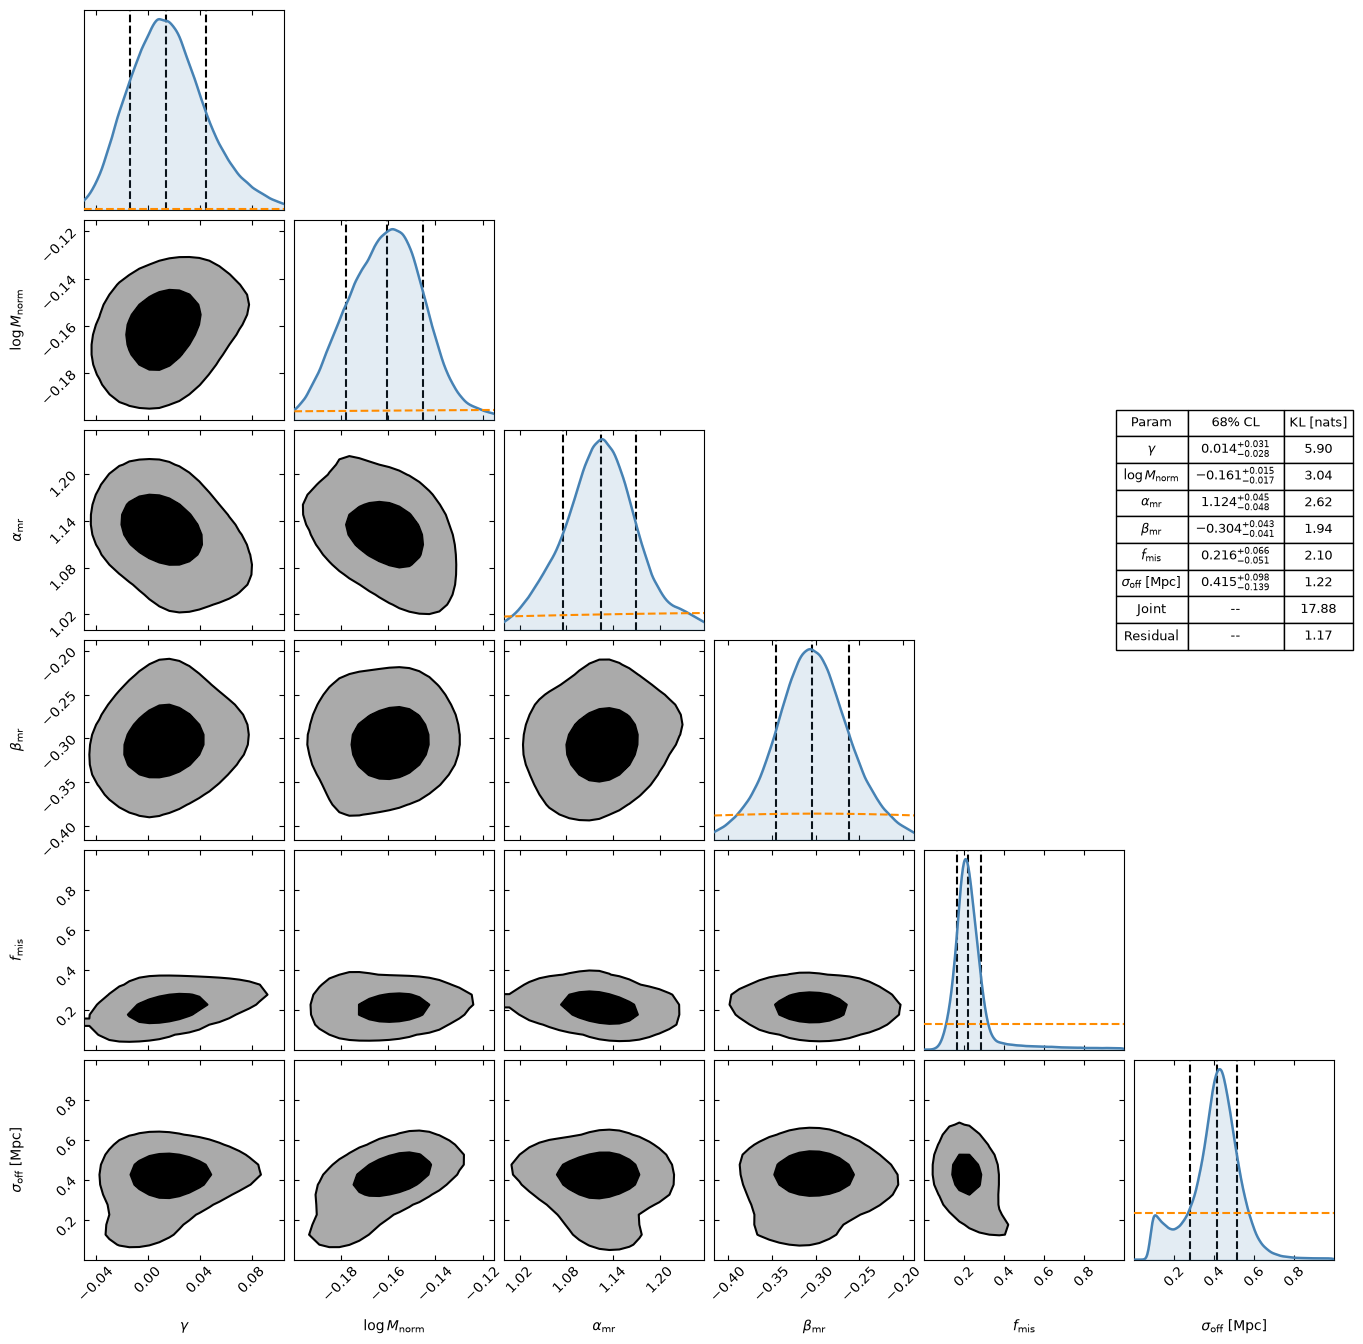

In [6]:
# ── Build the corner plot ────────────────────────────────────────────────
labels = [LABELS.get(p, p) for p in param_order]

# Restrict the plotted range to the central 99% credible interval for every
# parameter except f_mis/sigma_off, which keep their full data range (their
# posteriors are already well contained, unlike e.g. gamma_cm/alpha_mr,
# whose axes were previously dominated by rare wide nested-sampling
# excursions and collapsed the bulk of the posterior into a thin spike).
# corner.corner computes a float range as the weighted [50-50*f, 50+50*f]
# percentile interval, so this correctly accounts for the posterior weights.
FULL_RANGE_PARAMS = {"f_mis", "sigma_off"}
plot_range = []
for i, name in enumerate(param_order):
    if name in FULL_RANGE_PARAMS:
        col = samples_all[:, i]
        plot_range.append((float(col.min()), float(col.max())))
    else:
        plot_range.append(0.99)

fig = _corner.corner(
    samples_all, weights=weights_all,
    labels=labels,
    range=plot_range,
    truths=None,            # no truth lines — there is no truth for real data
    quantiles=[0.16, 0.50, 0.84],
    show_titles=False,      # no per-panel quantile titles
    plot_datapoints=False, fill_contours=True,
    levels=(0.39, 0.86),
    smooth=1.0,
    # Invisible histogram: still sets the correct (density-scaled) axis
    # limits and draws the 16/50/84th quantile dashed lines, but the
    # stepped bars themselves are hidden — the KDE curve drawn below
    # replaces them visually.
    hist_kwargs={"density": True, "alpha": 0.0},
)

k = len(param_order)
for i, name in enumerate(param_order):
    ax = fig.axes[i * k + i]
    xlo, xhi = ax.get_xlim()

    # Smooth 1D marginal via weighted Gaussian KDE (replaces the step
    # histogram) — same probability-density scale as the invisible
    # density=True histogram, so it lines up with the quantile lines and
    # (if present) the prior overlay below.
    kde = gaussian_kde(samples_all[:, i], weights=weights_all)
    xs = np.linspace(xlo, xhi, 400)
    ys = kde(xs)
    ax.plot(xs, ys, color="steelblue", lw=1.8, zorder=4)
    ax.fill_between(xs, ys, color="steelblue", alpha=0.15, zorder=3)
    ax.set_xlim(xlo, xhi)
    ax.set_ylim(0, 1.05 * ys.max())

    # Prior overlay, same convention as destacking.plotting.overlay_priors_on_corner.
    dist = PRIORS.get(name)
    if dist is not None:
        ax.plot(xs, dist.pdf(xs), color="darkorange", lw=1.5, ls="--", zorder=5)
        ax.set_xlim(xlo, xhi)

# Ticks inside the plot area, on every panel.
for ax in fig.axes:
    ax.tick_params(direction="in", top=True, right=True)

# ── Summary table in the blank upper-right corner ────────────────────────
# The upper-right triangle of a corner plot (columns > rows) is left blank
# by corner.corner. A rectangular block of grid cells with col_min > row_max
# is guaranteed to sit entirely inside that blank region, so its bounding
# box (in figure fraction coordinates) is a safe place for a fresh axes.
row_max, col_min = 4, 5   # 0-indexed; needs col_min > row_max
assert col_min > row_max
top_left_ax     = fig.axes[0 * k + col_min]
bottom_right_ax = fig.axes[row_max * k + (k - 1)]
bbox_tl = top_left_ax.get_position()
bbox_br = bottom_right_ax.get_position()
left, top     = bbox_tl.x0, bbox_tl.y1
right, bottom = bbox_br.x1, bbox_br.y0

table_ax = fig.add_axes([left, bottom, right - left, top - bottom])
table_ax.axis("off")
tbl = table_ax.table(
    cellText=table_rows,
    colLabels=["Param", "68% CL", "KL [nats]"],
    cellLoc="center",
    loc="center",
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.6)
tbl.auto_set_column_width(col=list(range(3)))

fig.savefig(OUT_PATH, dpi=150, bbox_inches="tight")
print(f"saved {OUT_PATH}")

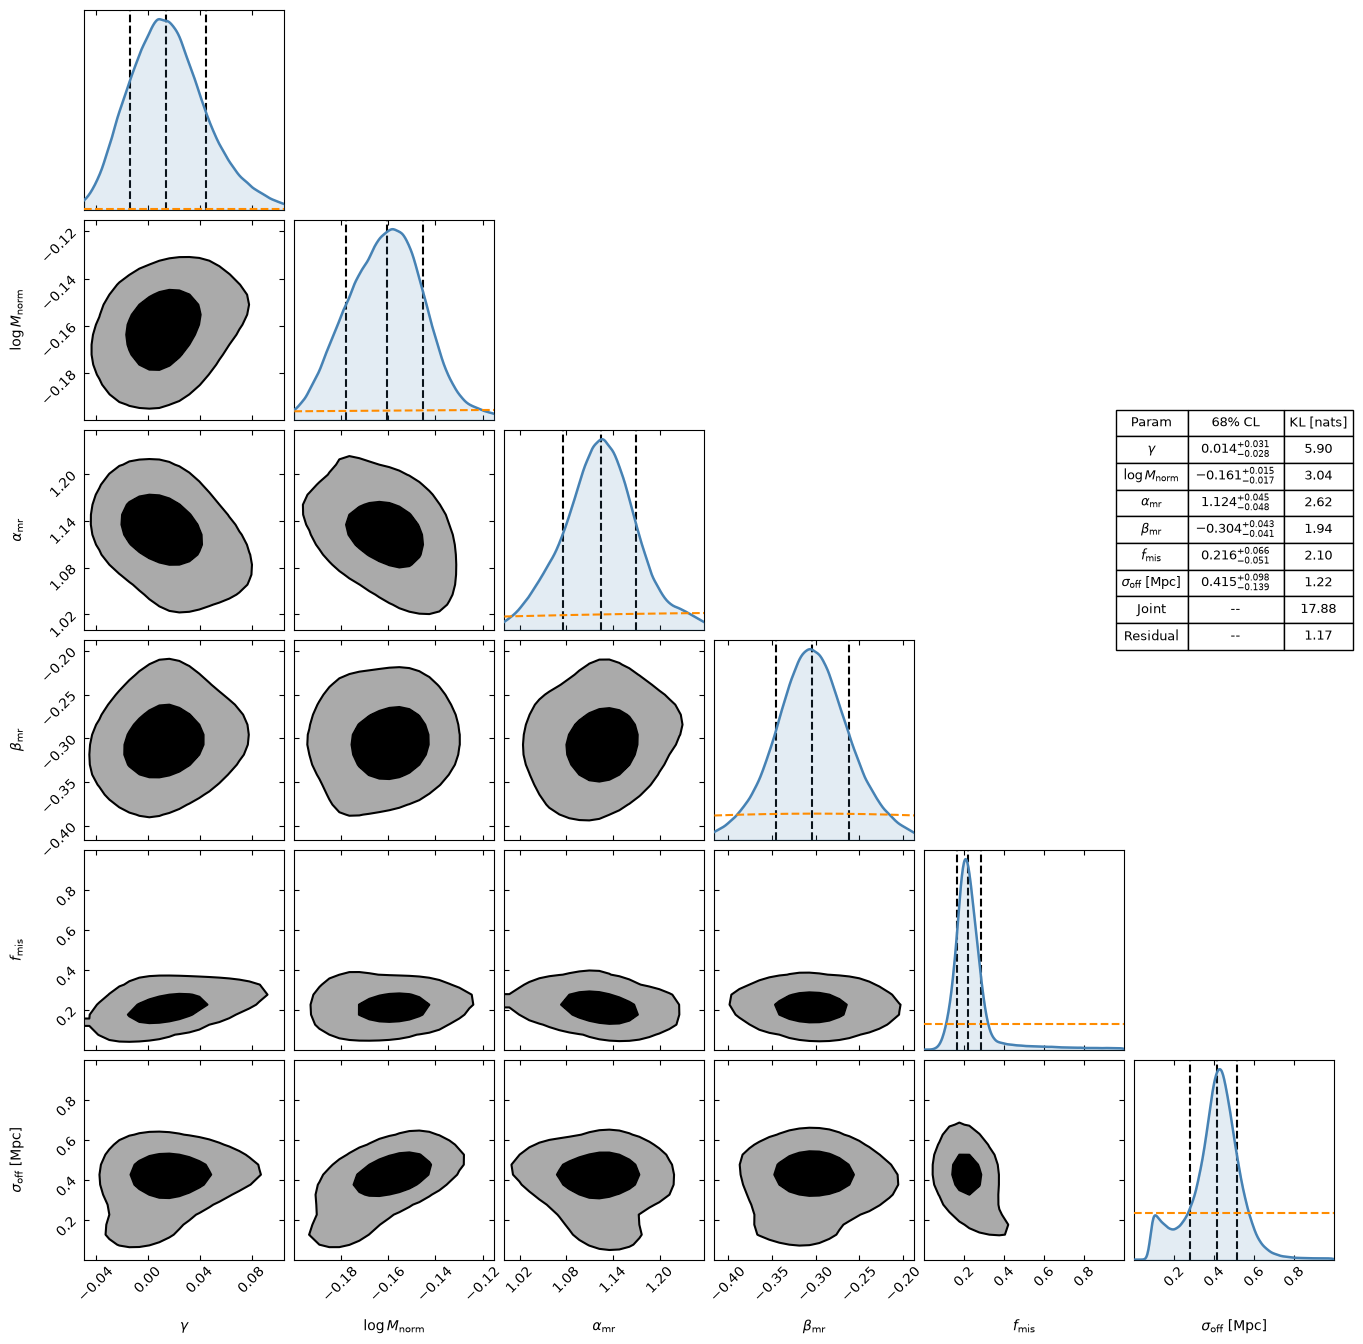

In [7]:
fig